In [7]:
import sklearn
from sklearn.datasets import load_digits, load_iris
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
import numpy as np
import pandas as pd

## Pilih salah satu dataset nyata dari sklearn.datasets

In [8]:
iris=load_iris()
X=iris.data

## Lakukan clustering dengan HDBSCAN

In [9]:
hdb=HDBSCAN(min_cluster_size=5)
labels=hdb.fit_predict(X)
print(pd.crosstab(iris.target, labels, rownames=['Actual'], colnames=['HDBSCAN']))

HDBSCAN   0   1
Actual         
0        50   0
1         0  50
2         0  50


## Laporkan hasil:
### - Jumlah cluster yang terbentuk.
### - Banyaknya noise.
### - Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu, dikarenakan visualisasi hanya dapat dilakukan hingga 3 dimensi).



In [19]:
n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f'jumlah cluster: {n_cluster}')
print(f'jumlah noise: {n_noise}')

jumlah cluster: 2
jumlah noise: 0


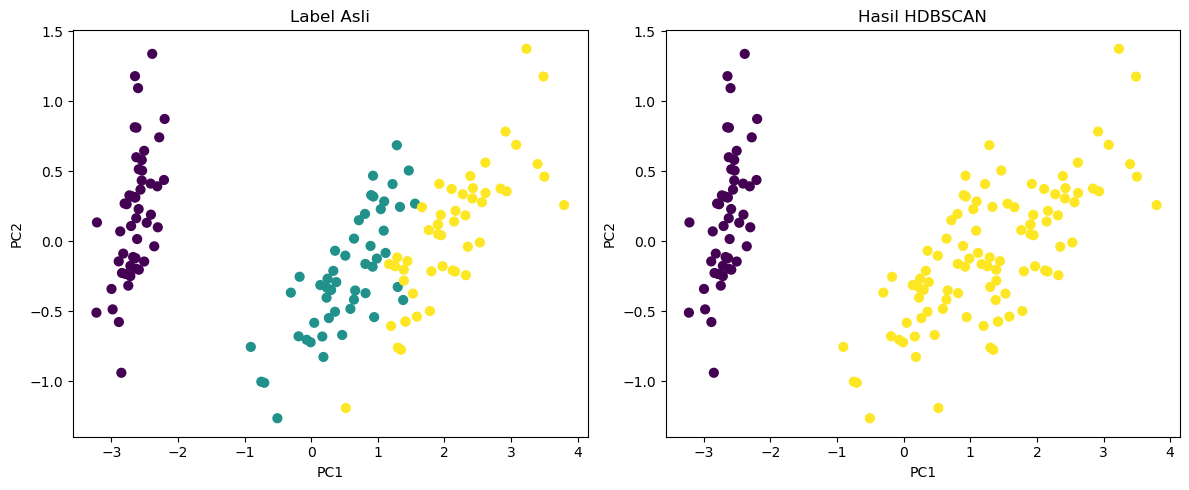

In [20]:
import matplotlib.pyplot as plt

X_pca = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap='viridis', s=40)
axes[0].set_title('Label Asli')

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=40)
axes[1].set_title('Hasil HDBSCAN')

for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

In [21]:
print('ARI',adjusted_rand_score(iris.target,labels),'\nNMI',normalized_mutual_info_score(iris.target,labels))

ARI 0.5681159420289855 
NMI 0.7336804366512104


hasil HDBSCAN hanya sebagian sesuai dengan label asli. Dari hasil clustering, tidak ada titik noise